In [17]:
autoreload
%autoreload 2
from sem2 import SEM2

NameError: name 'autoreload' is not defined

In [2]:
import pandas as pd
import numpy as np
import torch
from torch.utils.data import TensorDataset, DataLoader
from torch import nn
from engression.loss_func import energy_loss, energy_loss_two_sample
import matplotlib.pyplot as plt
import time

torch.manual_seed(0)

In [3]:
df = pd.read_csv('PoliticalDemocracy.csv')
var_names = df.columns.values.tolist()
dataset = torch.tensor(df.to_numpy()).to(dtype = torch.float32)
batch_size = 25
dataloader = DataLoader(TensorDataset(dataset), batch_size = batch_size, shuffle = True)
print(var_names)

['y1', 'y2', 'y3', 'y4', 'y5', 'y6', 'y7', 'y8', 'x1', 'x2', 'x3']


In [4]:
# Linear factor model
model_formula = "x1 <- ind60 + ex1; x2 <- ind60 + ex2; x3 <- ind60 + ex3; ind60, ex1, ex2 , ex3 ~ Normal(0,1)"
model = SEM2(model_formula)
observed_var = ["x1", "x2", "x3"]
x = dataset[:, [var_names.index(var) for var in observed_var]]
observed_index = [list(model.static_order()).index(var) for var in observed_var]

print(f'{observed_index = }')

observed_index = [4, 5, 6]


In [5]:
optimizer = torch.optim.Adam(model.parameters(), lr=1e-2)
for p in model.named_parameters():
    print(p)
model.train()
for i in range(2000):
    optimizer.zero_grad()
    sample1 = model(x.size(0))[:, observed_index]
    # print(f'{model(x.size(0)).shape = }')
    # print(model(x.size(0)))
    # assert False
    sample2 = model(x.size(0))[:, observed_index]
    loss, s1, s2 = energy_loss_two_sample(x, sample1, sample2)
    loss.backward()
    optimizer.step()
    if i == 0 or (i + 1) % 100 == 0:
        print(f'Iter {i + 1} | loss: {loss.item():.4f}, s1: {s1.item():.4f}, s2: {s2.item():.4f}')


('layer.x1._weight', Parameter containing:
tensor([[-0.0053,  0.3793]], requires_grad=True))
('layer.x1._bias', Parameter containing:
tensor([[-0.5820]], requires_grad=True))
('layer.x2._weight', Parameter containing:
tensor([[-0.5204, -0.2723]], requires_grad=True))
('layer.x2._bias', Parameter containing:
tensor([[0.1896]], requires_grad=True))
('layer.x3._weight', Parameter containing:
tensor([[-0.0140,  0.5607]], requires_grad=True))
('layer.x3._bias', Parameter containing:
tensor([[-0.0628]], requires_grad=True))
Iter 1 | loss: 7.7221, s1: 8.2913, s2: 1.1385
Iter 100 | loss: 5.1500, s1: 6.9599, s2: 3.6198
Iter 200 | loss: 3.8674, s1: 6.5687, s2: 5.4026
Iter 300 | loss: 2.3793, s1: 5.1525, s2: 5.5462
Iter 400 | loss: 2.1007, s1: 4.9555, s2: 5.7096
Iter 500 | loss: 1.9850, s1: 4.2497, s2: 4.5295
Iter 600 | loss: 1.5462, s1: 3.3560, s2: 3.6196
Iter 700 | loss: 1.7090, s1: 3.0631, s2: 2.7083
Iter 800 | loss: 1.4696, s1: 3.0417, s2: 3.1443
Iter 900 | loss: 1.3071, s1: 2.6810, s2: 2.747

In [6]:
beta = [model.layer[node].weight_matrix()[0][0, 0].squeeze().detach().numpy().tolist() for node in observed_var]
[beta[i] / beta[0] for i in range(3)]


[1.0, 2.1681208571040536, 1.917889219533944]

In [7]:
# Linear factor model (same as lavaan package example)
# Loss function: log-likelihood
formula_eps = "ex1, ex2, ex3, ey1, ey2, ey3, ey4, ey5, ey6, ey7, ey8, edem60, edem65 ~ Normal(0,1);" 
formula_epscov = "e15, e24, e26, e37, e48, e68 ~ Normal(0,1);"
formula_end = "ind60 ~ Normal(0,1); dem60 <- ind60 + edem60; dem65 <- ind60 + dem60 + edem65;"
formula_x = "x1 <- ind60 + ex1; x2 <- ind60 + ex2; x3 <- ind60 + ex3;"
formula_y1 = "y1 <- dem60 + ey1 + e15; y2 <- dem60 + ey2 + e24 + e26; y3 <- dem60 + ey3 + e37; y4 <- dem60 + ey4 + e24 + e48;"
formula_y2 = "y5 <- dem65 + ey5 + e15; y6 <- dem65 + ey6 + e26 + e68; y7 <- dem65 + ey7 + e37; y8 <- dem65 + ey8 + e48 + e68"
formula2 = formula_eps + formula_epscov + formula_end + formula_x + formula_y1 + formula_y2
lavaan_coefs = [1.483, 0.572, 0.837]

In [8]:
observed_var = var_names
x = dataset[:, [var_names.index(var) for var in observed_var]]
sd = torch.std(x, dim = 0)
print(sd)
x_normalized = torch.zeros_like(x)
for i in range(x.size(1)):
    x_normalized[:,i] = x[:,i] / sd[i]
sample_cov = torch.cov(torch.t(x))

tensor([2.6227, 3.9471, 3.2809, 3.3495, 2.6126, 3.3727, 3.2862, 3.2456, 0.7329,
        1.5107, 1.4057])


In [9]:
# Maximum likelihood (use sample from model to estimate variance)
model2 = SEM2(formula2)
observed_index = [list(model2.static_order()).index(var) for var in observed_var]
optimizer = torch.optim.Adam(model2.parameters(), lr=5e-2)
model2.train()
niter = 1000
coefs = np.zeros([niter, 3])
for i in range(niter):
    optimizer.zero_grad()
    model_sample = model2(x.size(0) * 10)[:, observed_index]
    model_cov = torch.cov(torch.t(model_sample))
    loss = torch.log(torch.det(model_cov)) + torch.trace(sample_cov @ torch.inverse(model_cov))
    # loss, s1, s2 = energy_loss(x_normalized, sample)
    loss.backward()
    optimizer.step()
    ind60_scale = model2.layer["x1"].weight_matrix()[0][0][0]
    dem60_scale = model2.layer["y1"].weight_matrix()[0][0][0]
    dem65_scale = model2.layer["y5"].weight_matrix()[0][0][0]
    coefs[i,:] = torch.tensor([model2.layer["dem60"].weight_matrix()[0][0][0] / ind60_scale * dem60_scale,
                               model2.layer["dem65"].weight_matrix()[0][0][0] / ind60_scale * dem65_scale,
                               model2.layer["dem65"].weight_matrix()[0][0][1] / dem60_scale * dem65_scale]).numpy()
    if i == 0 or (i + 1) % 1000 == 0:
        print(f'Iter {i + 1} | loss: {loss.item():.4f}, s1: {s1.item():.4f}, s2: {s2.item():.4f}')
        print(coefs[i, :])

Iter 1 | loss: 675.0543, s1: 2.7011, s2: 2.5259
[-2.06526685  0.81716031  0.43946937]
Iter 1000 | loss: 21.3550, s1: 2.7011, s2: 2.5259
[1.42769349 0.54379314 0.79043037]


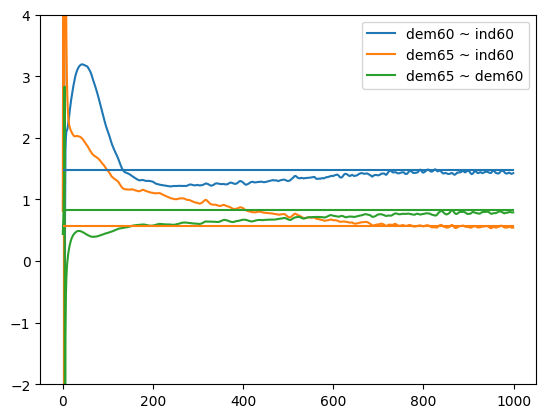

In [10]:
plt.plot(range(niter), coefs[:,0], label = "dem60 ~ ind60")
plt.plot(range(niter), coefs[:,1], label = "dem65 ~ ind60")
plt.plot(range(niter), coefs[:,2], label = "dem65 ~ dem60")
plt.hlines(lavaan_coefs, xmin = 0, xmax = niter, colors = ["C0", "C1", "C2"])
plt.ylim(-2, 4)
plt.legend()

In [11]:
# Energy loss minimization (100 * data size to estimate loss, normalize x first)
model3 = SEM2(formula2, device = "cpu")
x_normalized = x_normalized.to("cpu")
observed_index = [list(model3.static_order()).index(var) for var in observed_var]
optimizer = torch.optim.Adam(model3.parameters(), lr=1e-2)
model3.train()
niter = 3000
coefs = np.zeros([niter, 3])
for i in range(niter):
    optimizer.zero_grad()
    sample = model3(x.size(0) * 100)[:, observed_index]
    loss, s1, s2 = energy_loss(x_normalized, sample)
    loss.backward()
    optimizer.step()
    ind60_scale = model3.layer["x1"].weight_matrix()[0][0][0] * sd[var_names.index("x1")]
    dem60_scale = model3.layer["y1"].weight_matrix()[0][0][0] * sd[var_names.index("y1")]
    dem65_scale = model3.layer["y5"].weight_matrix()[0][0][0] * sd[var_names.index("y5")]
    coefs[i,:] = torch.tensor([model3.layer["dem60"].weight_matrix()[0][0][0] / ind60_scale * dem60_scale,
                               model3.layer["dem65"].weight_matrix()[0][0][0] / ind60_scale * dem65_scale,
                               model3.layer["dem65"].weight_matrix()[0][0][1] / dem60_scale * dem65_scale]).numpy()
    if i == 0 or (i + 1) % 1000 == 0:
        print(f'Iter {i + 1} | loss: {loss.item():.4f}, s1: {s1.item():.4f}, s2: {s2.item():.4f}')
        print(coefs[i, :])

Iter 1 | loss: 8.0278, s1: 9.1813, s2: 2.3069
[-0.11746719 -0.87102765 -3.94984961]
Iter 1000 | loss: 2.1872, s1: 4.4125, s2: 4.4508
[1.74252403 0.96514153 0.79173994]
Iter 2000 | loss: 2.1909, s1: 4.4230, s2: 4.4642
[1.56351542 0.66318262 0.80439353]
Iter 3000 | loss: 2.2300, s1: 4.4804, s2: 4.5008
[1.7051183  0.69100106 0.81456023]


In [12]:
# Run time of one iteration
start = time.time()
sample = model3(x.size(0) * 100)[:, observed_index]
loss, s1, s2 = energy_loss(x_normalized, sample)
loss.backward()
optimizer.step()
end = time.time()
print(end - start)

0.012356996536254883


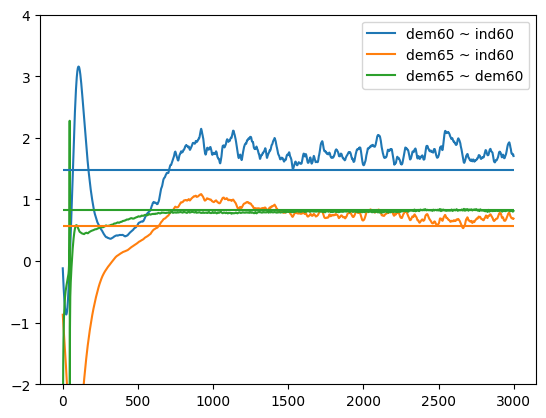

In [13]:
plt.plot(range(niter), coefs[:,0], label = "dem60 ~ ind60")
plt.plot(range(niter), coefs[:,1], label = "dem65 ~ ind60")
plt.plot(range(niter), coefs[:,2], label = "dem65 ~ dem60")
plt.hlines(lavaan_coefs, xmin = 0, xmax = niter, colors = ["C0", "C1", "C2"])
plt.ylim(-2, 4)
plt.legend()

In [14]:
# Energy loss minimization on GPU
model4 = SEM2(formula2, device = "cuda")
x_normalized = x_normalized.to("cuda")
observed_index = [list(model3.static_order()).index(var) for var in observed_var]
optimizer = torch.optim.Adam(model4.parameters(), lr=1e-2)
model4.train()
niter = 3000
coefs = np.zeros([niter, 3])
for i in range(niter):
    optimizer.zero_grad()
    sample = model4(x.size(0) * 100)[:, observed_index]
    loss, s1, s2 = energy_loss(x_normalized, sample)
    loss.backward()
    optimizer.step()
    ind60_scale = model4.layer["x1"].weight_matrix()[0][0][0] * sd[var_names.index("x1")]
    dem60_scale = model4.layer["y1"].weight_matrix()[0][0][0] * sd[var_names.index("y1")]
    dem65_scale = model4.layer["y5"].weight_matrix()[0][0][0] * sd[var_names.index("y5")]
    coefs[i,:] = torch.tensor([model4.layer["dem60"].weight_matrix()[0][0][0] / ind60_scale * dem60_scale,
                               model4.layer["dem65"].weight_matrix()[0][0][0] / ind60_scale * dem65_scale,
                               model4.layer["dem65"].weight_matrix()[0][0][1] / dem60_scale * dem65_scale]).numpy()
    if i == 0 or (i + 1) % 1000 == 0:
        print(f'Iter {i + 1} | loss: {loss.item():.4f}, s1: {s1.item():.4f}, s2: {s2.item():.4f}')
        print(coefs[i, :])

Iter 1 | loss: 8.4123, s1: 9.8451, s2: 2.8654
[-0.35410926  1.44282329 -0.33678269]
Iter 1000 | loss: 2.2068, s1: 4.4539, s2: 4.4942
[1.89865661 0.76695675 0.78120041]
Iter 2000 | loss: 2.1834, s1: 4.4220, s2: 4.4772
[1.66070771 0.64143193 0.84276068]
Iter 3000 | loss: 2.1897, s1: 4.4247, s2: 4.4701
[1.65913665 0.63960761 0.81254822]


In [15]:
# Run time of one iteration
start = time.time()
sample = model4(x.size(0) * 100)[:, observed_index]
loss, s1, s2 = energy_loss(x_normalized, sample)
loss.backward()
optimizer.step()
end = time.time()
print(end - start)

0.0076351165771484375


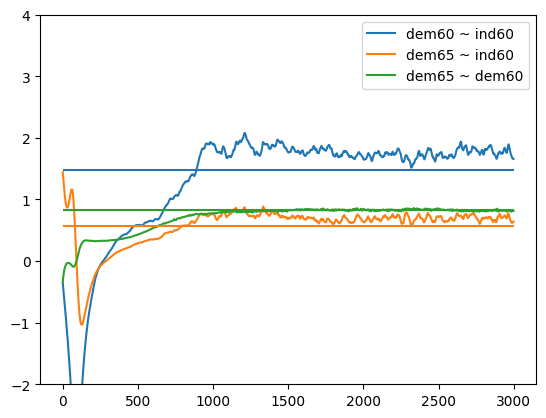

In [16]:
plt.plot(range(niter), coefs[:,0], label = "dem60 ~ ind60")
plt.plot(range(niter), coefs[:,1], label = "dem65 ~ ind60")
plt.plot(range(niter), coefs[:,2], label = "dem65 ~ dem60")
plt.hlines(lavaan_coefs, xmin = 0, xmax = niter, colors = ["C0", "C1", "C2"])
plt.ylim(-2, 4)
plt.legend()